In [1]:
#upload the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df=pd.read_csv("/content/AB_NYC_2019.csv.zip")

In [3]:
df.shape

(48895, 16)

In [4]:
df.columns

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [6]:
df.isnull()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,True,True,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48890,False,False,False,False,False,False,False,False,False,False,False,False,True,True,False,False
48891,False,False,False,False,False,False,False,False,False,False,False,False,True,True,False,False
48892,False,False,False,False,False,False,False,False,False,False,False,False,True,True,False,False
48893,False,False,False,False,False,False,False,False,False,False,False,False,True,True,False,False


In [7]:
df.isnull().sum()

,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [8]:
df[df['reviews_per_month'].isnull()]['number_of_reviews'].value_counts()

,count
number_of_reviews,
0,10052


In [9]:
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)



The reviews_per_month column contained 10,052 missing values. Further investigation revealed that all corresponding listings had zero number_of_reviews. Therefore, these missing values represent listings with no review activity, and replacing them with zero is a logical approach.



In [10]:
df = df.drop(columns=[
    'last_review',
    'id',
    'name',
    'host_id',
    'host_name'
])

In [11]:
df.shape

(48895, 11)

In [12]:
df.isnull().sum()

,0
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0
minimum_nights,0
number_of_reviews,0
reviews_per_month,0
calculated_host_listings_count,0


In [13]:
print("Price 95th percentile:", df['price'].quantile(0.95))

print("Minimum nights 95th percentile:", df['minimum_nights'].quantile(0.95))

Price 95th percentile: 355.0
Minimum nights 95th percentile: 30.0


In [14]:
price_limit = df['price'].quantile(0.95)
nights_limit = df['minimum_nights'].quantile(0.95)

df = df[
    (df['price'] > 0) &
    (df['price'] <= price_limit) &
    (df['minimum_nights'] <= nights_limit)
]

print(df.shape)

(45748, 11)


In [15]:
df = df.drop(columns=['neighbourhood'])

In [17]:
df = pd.get_dummies(
    df,
    columns=['neighbourhood_group', 'room_type'],
    drop_first=True,
    dtype=int
)

In [18]:
X = df.drop(columns=['price'])
y = df['price']

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [20]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

predictions = model.predict(X_test)

In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("MAE:", mean_absolute_error(y_test, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
print("R2 Score:", r2_score(y_test, predictions))

MAE: 38.3155402995448
RMSE: 52.54163068777636
R2 Score: 0.486788787487451


In [24]:
raw_df = pd.read_csv("/content/AB_NYC_2019.csv.zip")

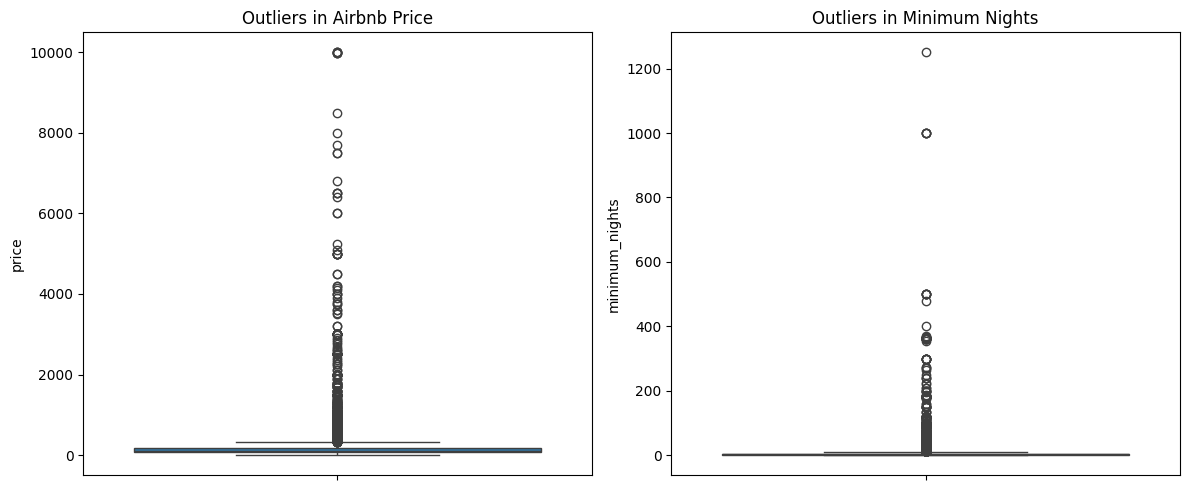

In [25]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=raw_df['price'])
plt.title('Outliers in Airbnb Price')

plt.subplot(1, 2, 2)
sns.boxplot(y=raw_df['minimum_nights'])
plt.title('Outliers in Minimum Nights')

plt.tight_layout()
plt.show()

### Outlier Detection and Treatment

Boxplots were generated for the `price` and `minimum_nights` columns to identify extreme values.

**Observations:**

1. The price distribution contains numerous extreme high-value observations, indicating a strong right-skew.
2. The minimum_nights column also contains several extreme values, including listings requiring hundreds of nights.
3. These extreme observations can influence the performance of a Linear Regression model.

**Treatment:**

The 95th percentile method was applied to both columns.

- Price threshold: $355
- Minimum nights threshold: 30 nights

Listings with zero or negative prices, prices above $355, or minimum-night requirements above 30 were excluded from the modelling dataset.

This treatment reduces the influence of extreme observations, although some legitimate high-priced and long-stay listings may also have been removed.

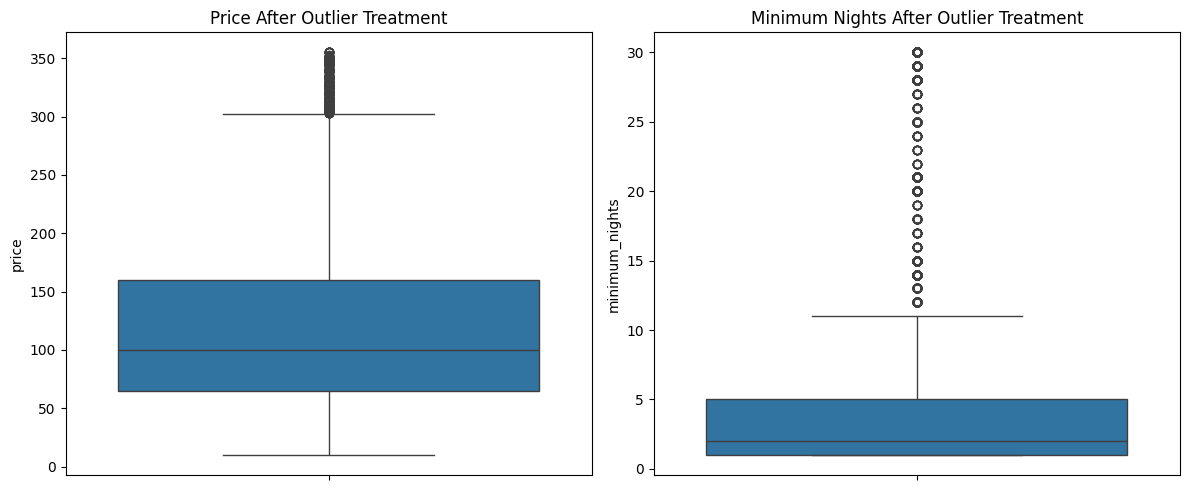

In [26]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=df['price'])
plt.title('Price After Outlier Treatment')

plt.subplot(1, 2, 2)
sns.boxplot(y=df['minimum_nights'])
plt.title('Minimum Nights After Outlier Treatment')

plt.tight_layout()
plt.show()

### Comparison After Outlier Treatment

After applying the 95th percentile method, the maximum price was reduced to $355 and the maximum minimum-night requirement was reduced to 30 days.

The distributions became more manageable for modelling. However, some observations remain outside the boxplot whiskers because the IQR-based boxplot identifies outliers differently from the percentile-based treatment used in this project.

This confirms that percentile-based treatment reduced extreme values without necessarily eliminating every statistical outlier.

In [27]:
print("Final dataset shape:", df.shape)
print("\nFinal columns:")
print(df.columns.tolist())

print("\nModel performance:")
print("MAE:", mean_absolute_error(y_test, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
print("R2 Score:", r2_score(y_test, predictions))

Final dataset shape: (45748, 14)

Final columns:
['latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'neighbourhood_group_Brooklyn', 'neighbourhood_group_Manhattan', 'neighbourhood_group_Queens', 'neighbourhood_group_Staten Island', 'room_type_Private room', 'room_type_Shared room']

Model performance:
MAE: 38.3155402995448
RMSE: 52.54163068777636
R2 Score: 0.486788787487451


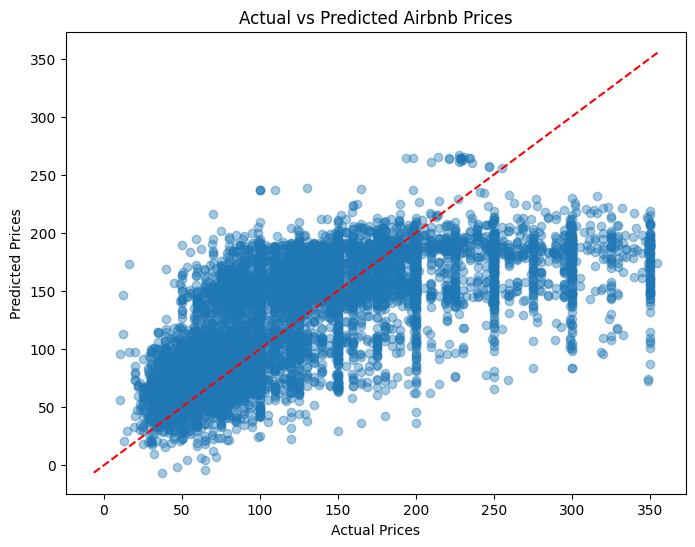

In [28]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, predictions, alpha=0.4)

# Create a 45-degree reference line
min_value = min(y_test.min(), predictions.min())
max_value = max(y_test.max(), predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color='red',
    linestyle='--'
)

plt.xlabel('Actual Prices')
plt.ylabel('Predicted Prices')
plt.title('Actual vs Predicted Airbnb Prices')

plt.show()

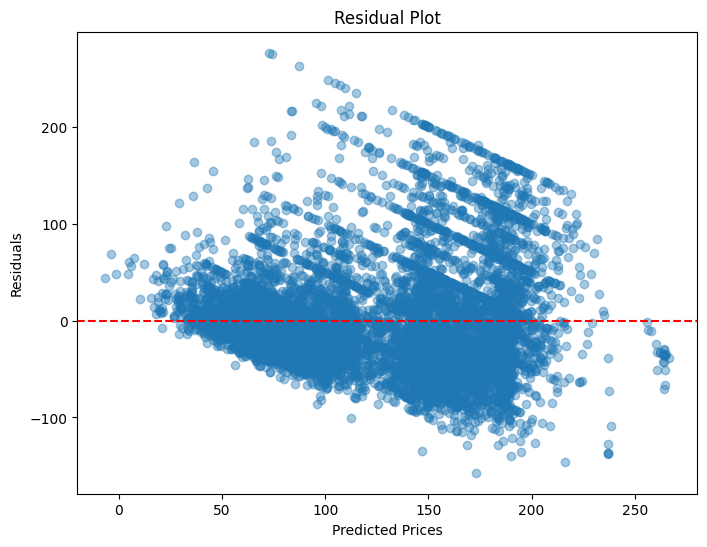

In [29]:
# Calculate residuals
residuals = y_test - predictions

# Create residual plot
plt.figure(figsize=(8, 6))

plt.scatter(predictions, residuals, alpha=0.4)

# Add zero reference line
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Predicted Prices')
plt.ylabel('Residuals')
plt.title('Residual Plot')

plt.show()

In [30]:

# Create a comparison DataFrame
results = pd.DataFrame({
    'Actual_Price': y_test,
    'Predicted_Price': predictions
})

# Calculate absolute prediction error
results['Absolute_Error'] = abs(
    results['Actual_Price'] - results['Predicted_Price']
)

# Find median actual price
median_price = results['Actual_Price'].median()

# Divide listings into two groups
cheap_listings = results[
    results['Actual_Price'] <= median_price
]

expensive_listings = results[
    results['Actual_Price'] > median_price
]

# Calculate average error for both groups
print("Median Price:", median_price)

print("Cheap Listings MAE:",
      cheap_listings['Absolute_Error'].mean())

print("Expensive Listings MAE:",
      expensive_listings['Absolute_Error'].mean())

Median Price: 100.0
Cheap Listings MAE: 29.01208535995143
Expensive Listings MAE: 48.17611343227906


### Task 7.3: Model Performance on Cheap vs. Expensive Listings

The model performs better on cheap Airbnb listings than on expensive listings when evaluated using Mean Absolute Error (MAE).

The test dataset was divided into two groups using the median actual price of $100.

The results were:

- Cheap listings MAE: $29.01
- Expensive listings MAE: $48.18

The model has a lower average prediction error for cheap listings. Its prediction errors are higher for expensive listings.

One possible reason is that expensive Airbnb properties may have more variation in their prices due to location, property characteristics, amenities, and other factors not fully captured by the model.

Therefore, the Linear Regression model predicts cheaper listings more accurately in terms of absolute dollar error.

# Project Conclusion – Airbnb Price Prediction

The objective of this project was to develop a Linear Regression model to predict Airbnb listing prices in New York City using the AB_NYC_2019 dataset.

The project involved data inspection, exploratory data analysis, missing-value treatment, duplicate checking, outlier identification and treatment, feature selection, categorical encoding, and model development.

Missing values in `reviews_per_month` were replaced with zero after confirming that the corresponding listings had no reviews. Irrelevant columns were removed, and the 95th percentile method was applied to reduce extreme values in `price` and `minimum_nights`.

Categorical variables were converted into numerical features using one-hot encoding. The dataset was divided into training and testing sets using an 80:20 split, with `random_state=42`.

A Linear Regression model was trained and evaluated using three performance metrics:

- **Mean Absolute Error (MAE):** 38.32
- **Root Mean Squared Error (RMSE):** 52.54
- **R² Score:** 0.4868

The R² score indicates that the model explains approximately 48.68% of the variation in Airbnb listing prices in the test dataset.

Overall, the project successfully demonstrates the complete basic machine-learning workflow for a regression problem. Although the model provides a useful baseline, its predictive performance could potentially be improved through additional feature engineering, more advanced regression algorithms, and further model optimization.

The project provided practical experience in data preprocessing, exploratory analysis, feature engineering, model training, and regression evaluation.